# 03 - Bias mitigation: pre, in and post-processing

Notebook 03 of the `callmefair` series. We take a stroke-risk model whose errors may fall unevenly on older vs. younger patients, apply mitigation techniques one at a time, and then let `BMGridSearch` try many combinations.

**What you'll learn**
- the three stages of bias mitigation and the `BMType` members that implement them;
- how to apply a pre-processing technique (Reweighing) and a post-processing technique (Equalized Odds) *by hand* with `BMManager`;
- how `BMGridSearch` automates this for several models and technique combinations;
- how to read the results (the table feeds notebook 04), with trade-off plots.

**Prerequisites:** [00_data_and_preprocessing.ipynb](00_data_and_preprocessing.ipynb) (data, groups, label) and [01_fairness_fundamentals.ipynb](01_fairness_fundamentals.ipynb) (metrics and the fairness score 𝓕; here 0 = fair, higher = more biased).

**Runtime**: about 2-4 minutes on a laptop.

## 1. The three stages

Mitigation can intervene at three points of the ML pipeline. `BMType` lists all techniques.

| Stage | When | `BMType` | What it does |
|---|---|---|---|
| **pre** | before training: change the training data | `preReweighing` | gives each (group, label) cell an instance weight so group and label look independent |
| | | `preDisparate` | Disparate Impact Remover: edits feature values to remove group information |
| | | `preLFR` | Learning Fair Representations: learns a fair latent representation |
| **in** | during training: fairness-aware learner | `inAdversarial` | Adversarial Debiasing: a second network tries to guess the group from the predictions |
| | | `inMeta` | MetaFair classifier with a fairness constraint |
| **post** | after training: change the predictions | `posCalibrated` | Calibrated Equalized Odds |
| | | `posEqqOds` | Equalized Odds |
| | | `posROC` | Reject Option Classification: flips decisions near the threshold |

Pre and post techniques work with *any* model. In-processing techniques bring their own model.

In [1]:
from fhg_examples import setup; setup()

## 2. Data and baseline

We study **age** on the stroke data (see notebook 00): group `age=1` (65 or older, stroke rate 15.5%) is the privileged reference, `age=0` (younger, 2.2%) the unprivileged group; the favorable label `stroke=1` is read as "flagged for follow-up care". The data set is small (5,109 rows, 249 positives), so no subsampling is needed.

> **Caveat.** The age gap largely reflects clinical risk. Base-rate differences are not by themselves unfair; fairness metrics ask whether errors and decisions are distributed equitably across groups. With so few positives, results also vary with the seed.

In [2]:
import pandas as pd
from fhg_examples.datasets import load, SPECS

spec = SPECS['stroke']
priv, unpriv = spec.attribute('age').groups
df = load('stroke')
pd.crosstab(df['age'], df[spec.label], margins=True)

stroke,0,1,All
age,,,
0,3992,90,4082
1,868,159,1027
All,4860,249,5109


Each (age, label) cell is small, so we use `test_size=0.2, val_size=0.2`: larger validation and test splits keep more positive cases per group. Next, the **baseline**: `BMInterface` makes the stratified train/validation/test split and serves it as aif360 datasets; a plain `LogisticRegression` is trained and `BMMetrics` reports performance and fairness on the test split. The decision threshold is tuned on the validation split.

Two small helpers keep the rest of the notebook short: `fit_proba` trains the model on the current training split (optionally with sample weights), and `evaluate` turns a `BMMetrics` object into a one-row table.

In [3]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from callmefair import BMInterface, BMMetrics, BMManager, BMType, BMGridSearch

bmI = BMInterface(df, spec.label, ['age'], test_size=0.2, val_size=0.2, random_state=0)
CLASSES = np.array([0, 1])
COLS = ['balanced_acc', 'spd', 'disparate_impact', 'eq_opp_diff', 'fair_score']

def evaluate(bmM, name):
    """One-row report with the columns we care about."""
    row = {**bmM.get_report(), 'fair_score': bmM.get_score()['overall_score']}
    return pd.DataFrame(row, index=[name])[COLS]

def fit_proba(bmI, sample_weight=None):
    """Train logistic regression; return (val, test) probability matrices."""
    X, y = bmI.get_train_xy()
    model = LogisticRegression(max_iter=1000).fit(X, y, sample_weight=sample_weight)
    return model.predict_proba(bmI.get_val_xy()[0]), model.predict_proba(bmI.get_test_xy()[0])


In [4]:
val_p, test_p = fit_proba(bmI)
bmM = BMMetrics(bmI, CLASSES, val_p, test_p, priv, unpriv)
baseline = evaluate(bmM, 'baseline')
baseline

,balanced_acc,spd,disparate_impact,eq_opp_diff,fair_score
baseline,0.668,-0.959,0.027,-0.958,1.0


Reading the row: `spd` (statistical parity difference) and `eq_opp_diff` are 0 when fair, `disparate_impact` is 1 when fair, and `fair_score` (𝓕) is 0 when fair. Details in notebook 01.

## 3. Pre-processing by hand: Reweighing

`BMManager` applies the techniques to the data held by `bmI`. **Reweighing** does not touch features or labels: it changes the training *instance weights* so that, after weighting, group and label are independent. Under-represented (group, label) cells get weight > 1.

In [5]:
bmMgr = BMManager(bmI, priv, unpriv)
bmMgr.pre_Reweighing()

train = bmI.get_train_BLD()
w = pd.DataFrame({'age': train.protected_attributes.ravel(),
                  'label': train.labels.ravel(),
                  'weight': train.instance_weights})
w.groupby(['age', 'label'])['weight'].agg(['count', 'mean'])

count   mean
age label              
0.0 0.0     2417  0.972
    1.0       53  2.266
1.0 0.0      499  1.134
    1.0       96  0.301

Before, every weight was 1; now they differ by group and label. The weights reach the model through `sample_weight`: we retrain with them and evaluate as before.

In [6]:
weights = bmI.get_train_BLD().instance_weights
val_p, test_p = fit_proba(bmI, sample_weight=weights)
bmM_rw = BMMetrics(bmI, CLASSES, val_p, test_p, priv, unpriv)
rw = evaluate(bmM_rw, 'preReweighing')
pd.concat([baseline, rw])

,balanced_acc,spd,disparate_impact,eq_opp_diff,fair_score
baseline,0.668,-0.959,0.027,-0.958,1.000
preReweighing,0.606,-0.187,0.768,-0.051,0.772


**Why `restore_BLD()`?** Pre-processing *replaces* the training data inside `bmI`. To start the next experiment from the original data, call `bmI.restore_BLD()`; otherwise techniques silently stack. `BMGridSearch` does this after every combination.

In [7]:
bmI.restore_BLD()
bmI.get_train_BLD().instance_weights[:3]   # back to the original weights (all 1)

array([1., 1., 1.])

## 4. Post-processing by hand: Equalized Odds

Post-processors fix the *decisions* of an already-trained model. They need to see the model's **scores** (P(favorable)) together with its thresholded labels, for both the validation set (to learn the correction) and the test set (to apply it). So we build two *prediction datasets*: copies of the validation/test datasets whose `.scores` hold the model probabilities and whose `.labels` hold the decisions at the tuned threshold (`bmM.best_class_thresh`). This is exactly what `BMGridSearch` does internally.

In [8]:
val_p, test_p = fit_proba(bmI)
bmM = BMMetrics(bmI, CLASSES, val_p, test_p, priv, unpriv)
thr = bmM.best_class_thresh

def prediction_bld(bld, proba):
    scores = proba[:, 1].reshape(-1, 1)
    bld.scores = scores
    bld.labels = np.where(scores > thr, bld.favorable_label, bld.unfavorable_label)
    return bld

val_pred = prediction_bld(bmI.get_val_BLD(), val_p)
test_pred = prediction_bld(bmI.get_test_BLD(), test_p)

In [9]:
val_post, test_post = bmMgr.pos_apply(BMType.posEqqOds, val_pred, test_pred)
bmM.set_pos_pred(test_post)          # metrics now use the post-processed decisions
pos = evaluate(bmM, 'posEqqOds')
pd.concat([baseline, rw, pos])

,balanced_acc,spd,disparate_impact,eq_opp_diff,fair_score
baseline,0.668,-0.959,0.027,-0.958,1.000
preReweighing,0.606,-0.187,0.768,-0.051,0.772
posEqqOds,0.458,-0.007,0.992,0.022,0.044


Post-processing changes the decisions only, so it can trade accuracy for fairness. Note that Equalized Odds is *randomised* and fitted on the validation split: with very few positives per group it can degenerate (for example predicting everyone favorable or unfavorable).

## 5. Grid search: many combinations, many models

Trying techniques by hand does not scale. `BMGridSearch` takes a model and a list of combinations (`bm_list`, a list of lists of `BMType`, applied pre, then post), and returns one row per combination plus the **baseline**. It restores the data between combinations. Pass `results_dir=None` to keep results in memory only (the default also writes a CSV).

We build `bm_list` with `itertools.product`: every pre x post pair plus each technique alone. Two models are compared: `LogisticRegression` and `XGBClassifier`. Because stroke has few positives, a single split is noisy: we **average over 3 split seeds** (`random_state` of `BMInterface`).

In [10]:
from itertools import product
from xgboost import XGBClassifier

pre = [BMType.preReweighing, BMType.preDisparate]
post = [BMType.posCalibrated, BMType.posEqqOds, BMType.posROC]
bm_list = [list(c) for c in product(pre, post)] + [[b] for b in pre + post]
len(bm_list), [[b.name for b in c] for c in bm_list[:3]]

(11,
 [['preReweighing', 'posCalibrated'],
  ['preReweighing', 'posEqqOds'],
  ['preReweighing', 'posROC']])

In [11]:
models = {'LogisticRegression': lambda: LogisticRegression(max_iter=1000),
          'XGBClassifier': lambda: XGBClassifier(n_estimators=200, n_jobs=-1)}
rows = []
for seed in range(3):
    bmI_s = BMInterface(df, spec.label, ['age'], test_size=0.2, val_size=0.2, random_state=seed)
    for name, make in models.items():
        rows += BMGridSearch(bmI_s, make(), bm_list, priv, unpriv).run_single_sensitive(results_dir=None)
res = pd.DataFrame(rows)
num = res.select_dtypes('number').columns
res = res.groupby(['model', 'BM'], sort=False)[list(num)].mean().reset_index()   # mean over seeds
res.shape

(24, 14)

Rows with the lowest fairness score 𝓕 (closest to fair):

In [12]:
SHOW = ['model', 'BM', 'balanced_acc', 'spd', 'disparate_impact', 'eq_opp_diff', 'fair_score']
res.sort_values('fair_score')[SHOW].head(6).round(3).reset_index(drop=True)

,model,BM,balanced_acc,spd,disparate_impact,eq_opp_diff,fair_score
0,LogisticRegression,preDisparate posEqqOds,0.470,0.002,1.004,0.026,0.228
1,LogisticRegression,posEqqOds,0.512,-0.000,1.000,0.026,0.240
2,XGBClassifier,preDisparate posEqqOds,0.547,0.006,1.006,-0.016,0.307
3,XGBClassifier,preDisparate posROC,0.548,-0.026,0.857,0.122,0.375
4,XGBClassifier,posEqqOds,0.522,-0.000,0.999,0.172,0.379
5,XGBClassifier,preReweighing posROC,0.529,-0.027,0.569,0.001,0.384


A compact view, 𝓕 by technique and model (the `baseline` row is the reference):

In [13]:
pivot = res.pivot(index='BM', columns='model', values='fair_score').round(3)
pivot.sort_values('LogisticRegression')

model,LogisticRegression,XGBClassifier
BM,,
preDisparate posEqqOds,0.228,0.307
posEqqOds,0.240,0.379
preReweighing posEqqOds,0.410,0.492
preReweighing posCalibrated,0.530,0.671
posCalibrated,0.546,0.691
preDisparate posCalibrated,0.582,0.837
posROC,0.632,0.534
preReweighing,0.675,1.000
preReweighing posROC,0.679,0.384


## 6. The trade-off, visualised

`res` holds one row per (model, combination), averaged over seeds. Each figure below shows it from a different angle.

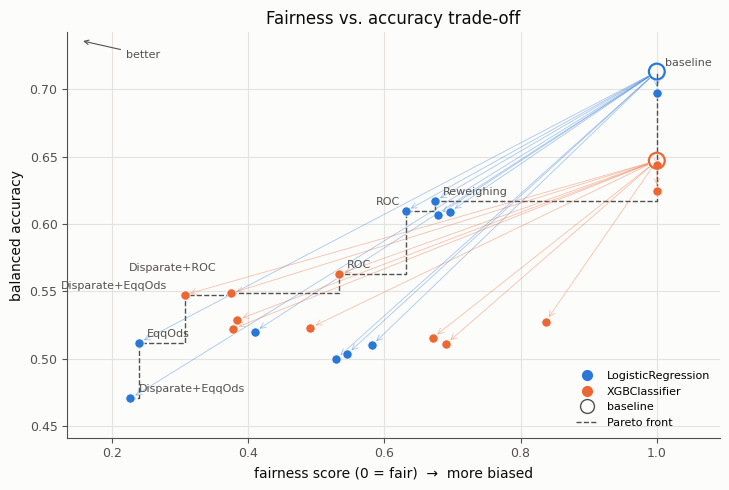

In [14]:
from callmefair.viz import plot_tradeoff, plot_metric_heatmap, plot_mitigation_effect, plot_fair_ranges
_ = plot_tradeoff(res)

**Look at:** the x axis is the fairness score 𝓕 (left = fairer), the y axis balanced accuracy (up = better). Hollow markers are baselines; arrows lead to their mitigations; the step line is the Pareto front (no point is both fairer and more accurate). Moving left usually costs some height.

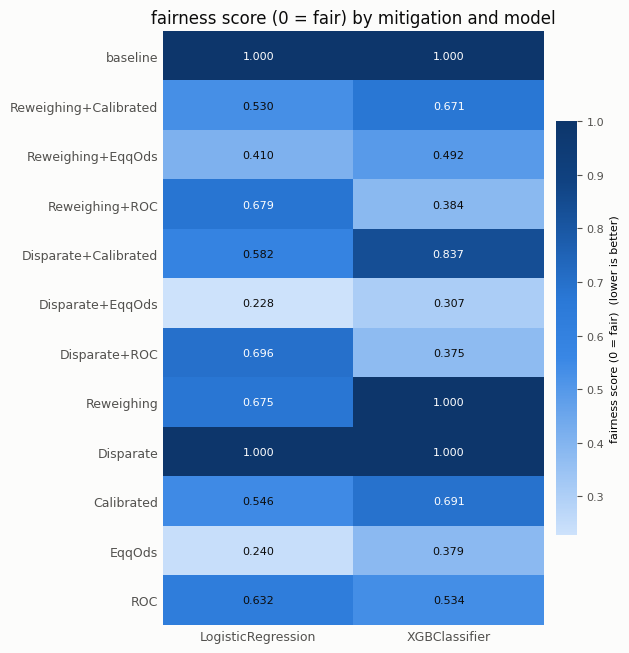

In [15]:
_ = plot_metric_heatmap(res, 'fair_score')

**Look at:** one cell per (technique, model); the baseline row is the reference. Rows whose cells are clearly lighter/darker than the baseline changed 𝓕 the most, and the two columns need not agree.

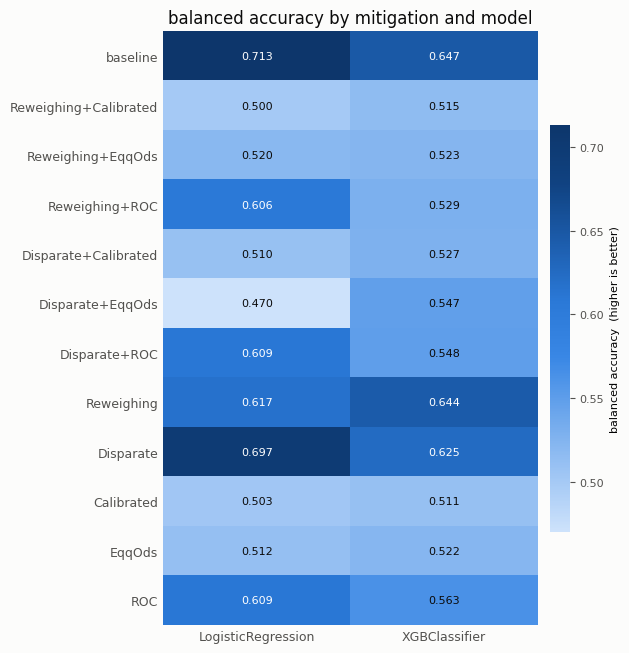

In [16]:
_ = plot_metric_heatmap(res, 'balanced_acc')

**Look at:** the same layout for balanced accuracy; compare with the previous heatmap to see which techniques buy fairness cheaply.

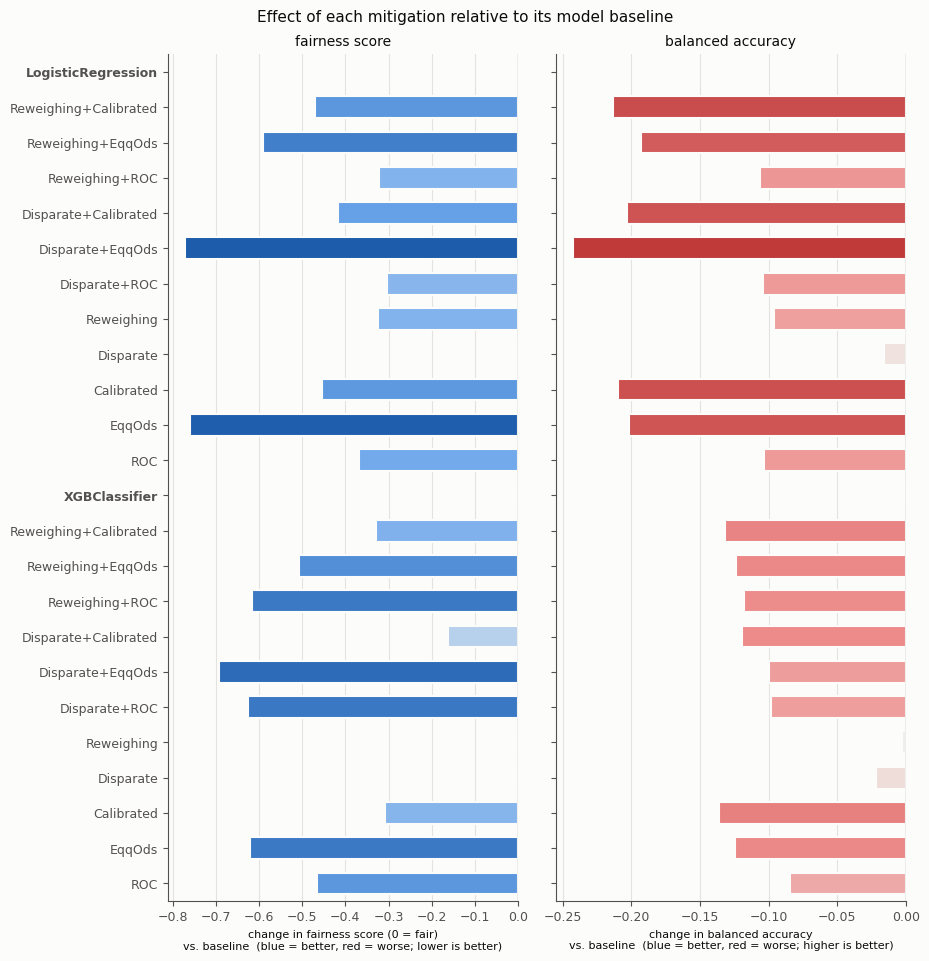

In [17]:
_ = plot_mitigation_effect(res)

**Look at:** bars show (mitigation - baseline of the same model). Bars that improve fairness while staying near zero for accuracy are the attractive ones.

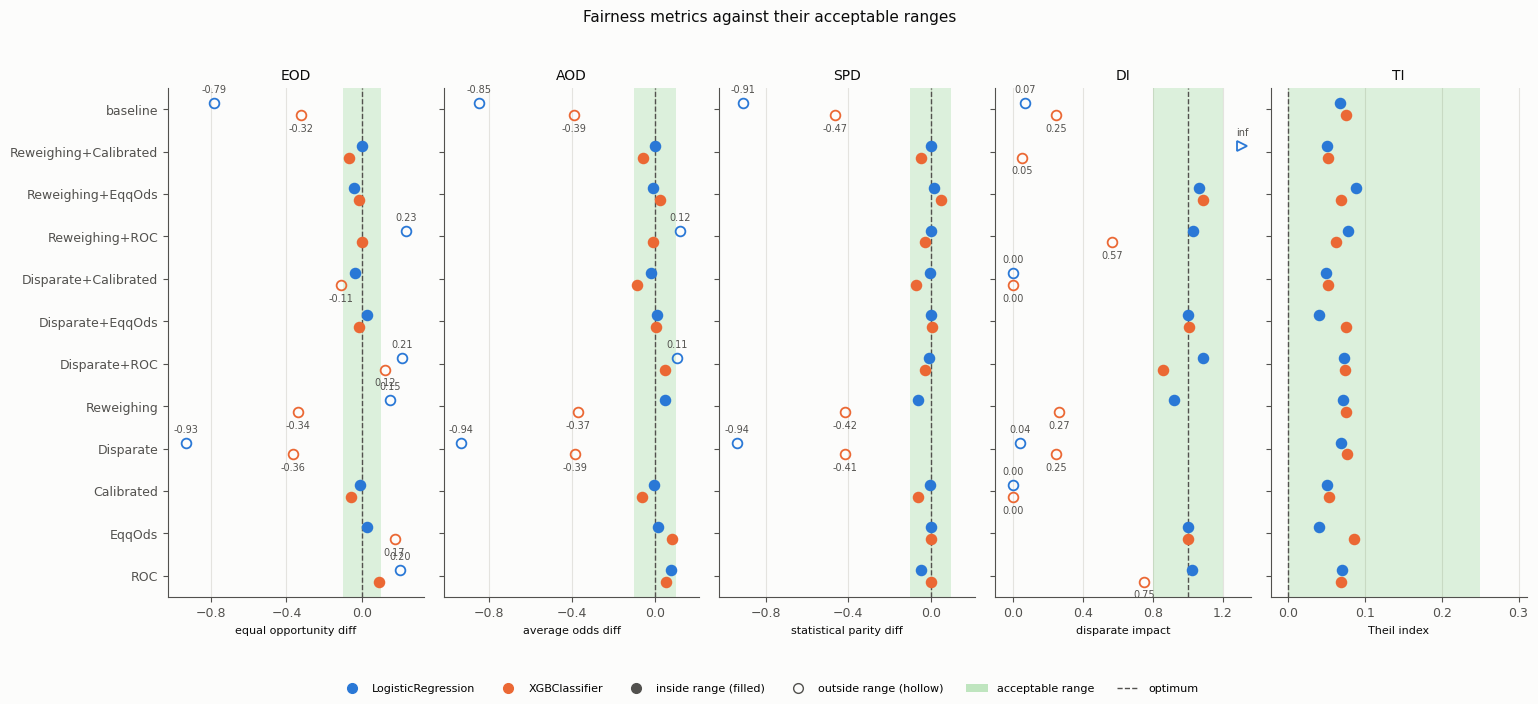

In [18]:
_ = plot_fair_ranges(res)

**Look at:** each panel is one fairness metric with its acceptable range shaded; filled points are inside the range, hollow ones outside. Compare how far the baselines sit from the shaded band with where the mitigated rows land, and which metrics (e.g. the disparate impact) are still out of range.

## 6. In-processing: Adversarial Debiasing (last section)

In-processing techniques are fairness-aware learners, so `BMGridSearch` gets `model=None` and a list holding the in-processing technique. The first row (`baseline`) is the *same* network trained with `debias=False`; the `inAD` row is trained with the adversary.

> **Caveat.** `AdversarialDebiasing` uses TensorFlow 1 graph mode and **disables eager execution for the whole kernel**. That is why this section comes last: restart the kernel before running any TensorFlow 2 code. Also, `inMeta` (MetaFair) with `tau>0` currently fails inside aif360 (known issue), so we do not run it.

In [19]:
import io, contextlib
import tensorflow as tf
tf.get_logger().setLevel('ERROR')   # silence TF deprecation notices

grid = BMGridSearch(bmI, None, [[BMType.inAdversarial]], priv, unpriv)
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    rows_ad = grid.run_single_sensitive(results_dir=None)   # hides TF training logs
ad = pd.DataFrame(rows_ad)
ad[SHOW].round(3)

,model,BM,balanced_acc,spd,disparate_impact,eq_opp_diff,fair_score
0,AdversarialDebiasing,baseline,0.651,-0.726,0.106,-0.679,1.0
1,AdversarialDebiasing,inAD,0.635,-0.355,0.632,-0.125,1.0


## Summary

- **pre** (`preReweighing`, `preDisparate`, `preLFR`) changes the training data; **in** (`inAdversarial`, `inMeta`) changes the learner; **post** (`posCalibrated`, `posEqqOds`, `posROC`) changes the decisions.
- `BMManager` applies one technique to the data in `bmI`; call `bmI.restore_BLD()` between experiments. Post-processing needs score-carrying prediction datasets.
- `BMGridSearch` runs baseline + all combinations for a model and returns the rows (pass a folder as `results_dir` to also save them as CSV).

**How to read the results**
- On stroke/age, the unmitigated models have the worst possible 𝓕 (capped at 1). Post-processing (Equalized Odds in particular) lowers it the most, and every mitigation costs balanced accuracy: read the trade-off plot, not 𝓕 alone. Combining pre + post rarely beats the best post-processor alone.
- Always compare against the `baseline` row of the *same model*; XGBoost and logistic regression start from different levels of bias.
- Caveats: with 249 positives results depend on the split seed (we average 3); few positives per group make Equalized Odds unstable; the age gap largely reflects clinical risk, so a base-rate difference is not by itself unfair; a lower 𝓕 on one attribute does not guarantee fairness on another.

**Next:** [04_tradeoff_map.ipynb](04_tradeoff_map.ipynb) turns tables like the one above into a fairness-accuracy trade-off map.